# Stage 10b — Manuscript SHAP figures (Figures 2–7)

Rebuilds every figure in the *SHAP interpretation* section of the manuscript (3.3 Global SHAP importance and 3.4 Local SHAP explanations and mapped substructures) from the SHAP values **already computed and saved** by `10_interpretation_and_mechanistic_explanation.ipynb` (Section 3). SHAP is not recomputed here and no model is loaded; the saved tables are checked for additivity against the Stage-08 predictions before anything is drawn.

| Figure | Content | Code cell(s) |
|---|---|---|
| Fig. 2 | Global SHAP importance (bars) and beeswarm summaries, CatBoost and ExtraTrees (a–d) | 4–5 |
| Fig. 3 | Local SHAP waterfall plots: highest / median / lowest predicted compound per model (a–f) | 6–7 |
| Fig. 4 | Morgan environments mapped onto the six locally explained compounds (a–f) | 8–9 |
| Fig. 5 | ExtraTrees vs CatBoost agreement of local Morgan-bit attributions (hexbin) | 11 |
| Fig. 6 | Mean local SHAP of recurring Morgan environments, bootstrap 95% CI | 12–13 |
| Fig. 7 | Observed median pIC50 difference, carriers vs noncarriers, bootstrap 95% CI | 12, 14 |

Tables behind the figures are also written as CSV (Table 3 long form, Table 4, Table 5, Table A1). Cell 15 collects the numbers quoted in the manuscript text (top features, family shares, case predictions, agreement statistics) from the current models.

**Nothing is hardcoded.** The six locally explained compounds are the highest-, median- and lowest-predicted locked-test compound of each model, taken from `locked_test_predictions_all_models.csv` exactly as in Stage 10, Section 9a. The environments in Figs 6–7 are chosen from the saved SHAP values by a stated rule (cell 12), and all numbers, labels and legends are computed from the current tables and structures.

Outputs go to `outputs/10_interpretation/manuscript_figures/`.

In [1]:
# 1. Setup, switches and imports
import sys, re, io, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError("Open this notebook from the BRD4 QSAR project folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from scipy import stats
from IPython.display import display
import shap
from rdkit import Chem, rdBase
from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors, rdFingerprintGenerator
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image

from src.utils import OUTPUTS, load_config, setup_plotting

warnings.filterwarnings("ignore", category=FutureWarning)

MODELS = ["ExtraTreesRegressor", "CatBoostRegressor"]
MODEL_SHORT = {"ExtraTreesRegressor": "ExtraTrees", "CatBoostRegressor": "CatBoost"}

# ---------------------------------------------------------------- switches
TOP_N_GLOBAL = 20              # features drawn in Fig. 2
TOP_N_LOCAL = 12               # a present Morgan bit is mapped if it is among the 12 largest |SHAP| of its molecule (as in Stage 10)
WATERFALL_MAX_DISPLAY = 15     # 14 features + one "other features" bar
MIN_CARRIERS = 25              # minimum test-set carriers for a recurring environment (Figs 6-7)
N_PER_DIRECTION = 7            # rule-based selection only: most positive and most negative environments to show
N_BOOT = 2000                  # molecule-bootstrap replicates for the confidence intervals
HEX_GRIDSIZE = 55              # Fig. 5
SAVE_DPI = 300                 # PNG resolution (SVG is also written for the vector figures 5-7)
SEED = 42

setup_plotting()
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": SAVE_DPI, "font.family": "DejaVu Sans", "svg.fonttype": "none"})

OUT_DIR = OUTPUTS / "10_interpretation"
FIG_DIR = OUT_DIR / "manuscript_figures"
TAB_DIR = FIG_DIR / "tables"
SHAP_TABLE_DIR = OUT_DIR / "shap_values"                       # written by Stage 10, Section 3
LEGACY_SHAP_DIR = OUTPUTS / "10_shap_interpretation" / "tables"   # older location, used only if the new one is empty
for folder in (FIG_DIR, TAB_DIR):
    folder.mkdir(parents=True, exist_ok=True)

saved_files = []
def save_figure(fig, stem, svg=True):
    """Save a figure as PNG (and optionally SVG) in the manuscript-figure folder."""
    png = FIG_DIR / f"{stem}.png"
    fig.savefig(png, dpi=SAVE_DPI, bbox_inches="tight", facecolor="white")
    saved_files.append(png)
    if svg:
        svg_path = FIG_DIR / f"{stem}.svg"
        fig.savefig(svg_path, bbox_inches="tight", facecolor="white")
        saved_files.append(svg_path)

def render_to_array(fig, dpi=SAVE_DPI):
    """Rasterise a finished figure to an RGB array and close it (used to tile shap's own plots into panels)."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    buf.seek(0)
    return np.asarray(Image.open(buf).convert("RGB"))

print("Project:", PROJECT_ROOT)
print("Figure folder:", FIG_DIR)
print("shap", shap.__version__)

Project: c:\Users\USER\Documents\E\Code
Figure folder: C:\Users\USER\Documents\E\Code\outputs\10_interpretation\manuscript_figures
shap 0.49.1


In [2]:
# 2. Load configuration and the Stage 02-08 inputs (same files and checks as Stage 10, Section 2)
cfg = load_config()
FP_SIZE = int(cfg.get("fingerprint_bits", 2048))
FP_RADIUS = int(cfg.get("fingerprint_radius", 2))
USE_CHIRALITY = bool(cfg.get("use_chirality", True))
SEED = int(cfg.get("seed", SEED))

MORGAN = rdFingerprintGenerator.GetMorganGenerator(radius=FP_RADIUS, fpSize=FP_SIZE, includeChirality=USE_CHIRALITY)

SELECTED_FILE = OUTPUTS / "05_feature_selection/tables/selected_features.csv"
TEST_IDS_FILE = OUTPUTS / "04_train_test_split/tables/test_ids.csv"
CLEANED_FILE = OUTPUTS / "02_clean_data/tables/cleaned_activity.csv"
FEATURES_FILE = OUTPUTS / "03_feature_generation/tables/all_features.parquet"
PREDICTIONS_FILE = OUTPUTS / "08_final_model_evaluation/tables/locked_test_predictions_all_models.csv"

missing = [p for p in [SELECTED_FILE, TEST_IDS_FILE, CLEANED_FILE, FEATURES_FILE, PREDICTIONS_FILE] if not p.is_file()]
if missing:
    raise FileNotFoundError("Missing prerequisite output(s):\n" + "\n".join(map(str, missing)) + "\nRun Stages 02-05 and 08 first.")

selected_features = pd.read_csv(SELECTED_FILE)["feature"].astype(str).tolist()
if len(selected_features) != 250 or len(set(selected_features)) != 250:
    raise ValueError(f"Expected exactly 250 unique Stage 05 features; found {len(selected_features)}.")
morgan_features = [f for f in selected_features if f.startswith("ecfp4_")]
descriptor_features = [f for f in selected_features if not f.startswith("ecfp4_")]

test_ids = pd.read_csv(TEST_IDS_FILE, dtype={"chembl_id": str})
test_ids["chembl_id"] = test_ids.chembl_id.astype(str)
if test_ids.chembl_id.duplicated().any():
    raise ValueError("Duplicate IDs in locked test ID file.")
test_index = pd.Index(test_ids.chembl_id, name="chembl_id")

structures = pd.read_csv(CLEANED_FILE, usecols=["chembl_id", "canonical_smiles"], dtype={"chembl_id": str})
smiles_by_id = structures.assign(chembl_id=structures.chembl_id.astype(str)).set_index("chembl_id").canonical_smiles
if set(test_index) - set(smiles_by_id.index):
    raise ValueError("Some test molecules lack canonical SMILES.")

predictions = pd.read_csv(PREDICTIONS_FILE, dtype={"chembl_id": str})
predictions["chembl_id"] = predictions.chembl_id.astype(str)
predictions = predictions.loc[predictions.model.isin(MODELS)].copy()
need = {"model", "chembl_id", "predicted_pIC50", "observed_pIC50"}
if need - set(predictions.columns):
    raise ValueError(f"Stage 08 predictions missing columns: {need - set(predictions.columns)}")
observed = (predictions.loc[predictions.model == MODELS[0]].drop_duplicates("chembl_id")
            .set_index("chembl_id").observed_pIC50.reindex(test_index))

X_test = pd.read_parquet(FEATURES_FILE, columns=selected_features)
X_test.index = X_test.index.astype(str)
X_test = X_test.reindex(test_index).apply(pd.to_numeric, errors="coerce")
if not np.isfinite(X_test.to_numpy(dtype=float)).all():
    raise ValueError("Non-finite values in fixed-250 test features; no imputation is used.")

print(f"Features: {len(selected_features)} ({len(morgan_features)} Morgan bits + {len(descriptor_features)} descriptors)")
print(f"Locked test molecules: {len(test_index):,}")

Features: 250 (103 Morgan bits + 147 descriptors)
Locked test molecules: 1,283


In [3]:
# 3. Load the SHAP values saved by Stage 10 (Section 3) and verify them; nothing is recomputed
ADDITIVITY_TOL = 1e-2     # max |expected_value + sum(SHAP) - Stage-08 prediction|

def find_saved_shap(model_name):
    for folder in (SHAP_TABLE_DIR, LEGACY_SHAP_DIR):
        path = folder / f"test_shap_values_{model_name}.parquet"
        if path.is_file():
            return path
    raise FileNotFoundError(f"No saved SHAP table for {model_name} in {SHAP_TABLE_DIR} or {LEGACY_SHAP_DIR}. "
                            "Run Section 3 of 10_interpretation_and_mechanistic_explanation.ipynb first.")

provenance_file = SHAP_TABLE_DIR / "shap_provenance.csv"
provenance = pd.read_csv(provenance_file).set_index("model") if provenance_file.is_file() else None

shap_by_model, pred_by_model, base_values = {}, {}, {}
for model_name in MODELS:
    path = find_saved_shap(model_name)
    saved = pd.read_parquet(path)
    saved["chembl_id"] = saved["chembl_id"].astype(str)
    if saved.chembl_id.duplicated().any() or set(saved.chembl_id) != set(test_index):
        raise ValueError(f"{model_name}: SHAP table {path.name} does not cover exactly the locked test molecules.")
    missing_cols = [f for f in selected_features if f not in saved.columns]
    if missing_cols:
        raise ValueError(f"{model_name}: SHAP table lacks {len(missing_cols)} of the fixed 250 features (e.g. {missing_cols[:3]}).")
    values = saved.set_index("chembl_id").reindex(test_index)[selected_features].to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError(f"{model_name}: non-finite SHAP values.")

    # Stage-08 predictions are the reference the SHAP values must add up to
    pred = (predictions.loc[predictions.model == model_name].drop_duplicates("chembl_id")
            .set_index("chembl_id").predicted_pIC50.reindex(test_index).to_numpy(dtype=float))
    if np.isnan(pred).any():
        raise ValueError(f"{model_name}: Stage-08 predictions missing for some locked test molecules.")

    # baseline: saved expected value if available, otherwise implied by additivity (and required to be constant)
    implied = pred - values.sum(axis=1)
    if provenance is not None and model_name in provenance.index:
        base, base_source = float(provenance.loc[model_name, "expected_value"]), "shap_provenance.csv"
    else:
        base, base_source = float(np.median(implied)), "implied by additivity"
    gap = float(np.max(np.abs(base + values.sum(axis=1) - pred)))
    if gap > ADDITIVITY_TOL:
        raise ValueError(f"{model_name}: saved SHAP values are not additive with the Stage-08 predictions (max gap {gap:.4g}). "
                         "The SHAP table and the prediction table come from different fits; re-run Stage 10 Section 3.")

    shap_by_model[model_name] = pd.DataFrame(values, index=test_index, columns=selected_features)
    pred_by_model[model_name] = pd.Series(pred, index=test_index, name="predicted_pIC50")
    base_values[model_name] = base
    print(f"{model_name}: {values.shape[0]:,} x {values.shape[1]} saved SHAP values ({path.parent.name}/{path.name}) | "
          f"baseline {base:.4f} ({base_source}) | additivity gap {gap:.1e}")

ExtraTreesRegressor: 1,283 x 250 saved SHAP values (shap_values/test_shap_values_ExtraTreesRegressor.parquet) | baseline 6.2296 (shap_provenance.csv) | additivity gap 1.8e-09
CatBoostRegressor: 1,283 x 250 saved SHAP values (shap_values/test_shap_values_CatBoostRegressor.parquet) | baseline 6.2296 (shap_provenance.csv) | additivity gap 1.6e-14


## Figure 2 — Global SHAP importance (Section 3.3)
Mean |SHAP| over the locked test set; panels (a, c) are bar charts of the top 20 features and (b, d) the matching beeswarm summaries (red = high feature value, blue = low).

In [4]:
# 4. Global importance tables and the family shares quoted in Section 3.3
def feature_family(name):
    if name.startswith("ecfp4_"):
        return "Morgan"
    if name.startswith("mordred2d_"):
        return "Mordred 2D"
    if name.startswith("phys_"):
        return "Physicochemical"
    return "Other"

tables = []
for m in MODELS:
    mean_abs = shap_by_model[m].abs().mean().sort_values(ascending=False)
    tables.append(pd.DataFrame({
        "model": m, "rank": np.arange(1, len(mean_abs) + 1), "feature": mean_abs.index,
        "mean_abs_shap": mean_abs.values, "mean_shap": shap_by_model[m].mean().reindex(mean_abs.index).values,
        "family": [feature_family(f) for f in mean_abs.index]}))
global_imp = pd.concat(tables, ignore_index=True)
global_imp.to_csv(TAB_DIR / "global_shap_importance_both_models.csv", index=False)

family_share = (global_imp.groupby(["model", "family"], sort=False).mean_abs_shap.sum()
                .groupby(level=0).transform(lambda s: 100 * s / s.sum()).rename("share_of_summed_abs_SHAP_pct").reset_index())
family_share.to_csv(TAB_DIR / "family_share_of_abs_shap.csv", index=False)

print("Top 5 features by mean |SHAP|:")
display(global_imp.groupby("model", sort=False).head(5)[["model", "rank", "feature", "mean_abs_shap", "mean_shap"]].round(4))
print("Share of summed mean |SHAP| by feature family (%):")
display(family_share.round(1))

Top 5 features by mean |SHAP|:


,model,rank,feature,mean_abs_shap,mean_shap
0,ExtraTreesRegressor,1,ecfp4_361,0.2895,-0.1050
1,ExtraTreesRegressor,2,ecfp4_1164,0.1387,0.0186
2,ExtraTreesRegressor,3,ecfp4_1722,0.0760,0.0077
3,ExtraTreesRegressor,4,ecfp4_318,0.0684,0.0062
4,ExtraTreesRegressor,5,ecfp4_875,0.0484,-0.0037
250,CatBoostRegressor,1,ecfp4_361,0.1686,-0.0243
251,CatBoostRegressor,2,ecfp4_1722,0.0758,0.0021
252,CatBoostRegressor,3,mordred2d_SpMax_A,0.0737,0.0043
253,CatBoostRegressor,4,ecfp4_875,0.0642,-0.0023
254,CatBoostRegressor,5,ecfp4_318,0.0563,0.0035


Share of summed mean |SHAP| by feature family (%):


,model,family,share_of_summed_abs_SHAP_pct
0,ExtraTreesRegressor,Morgan,67.8
1,ExtraTreesRegressor,Mordred 2D,32.1
2,ExtraTreesRegressor,Physicochemical,0.1
3,CatBoostRegressor,Morgan,35.9
4,CatBoostRegressor,Mordred 2D,63.6
5,CatBoostRegressor,Physicochemical,0.6


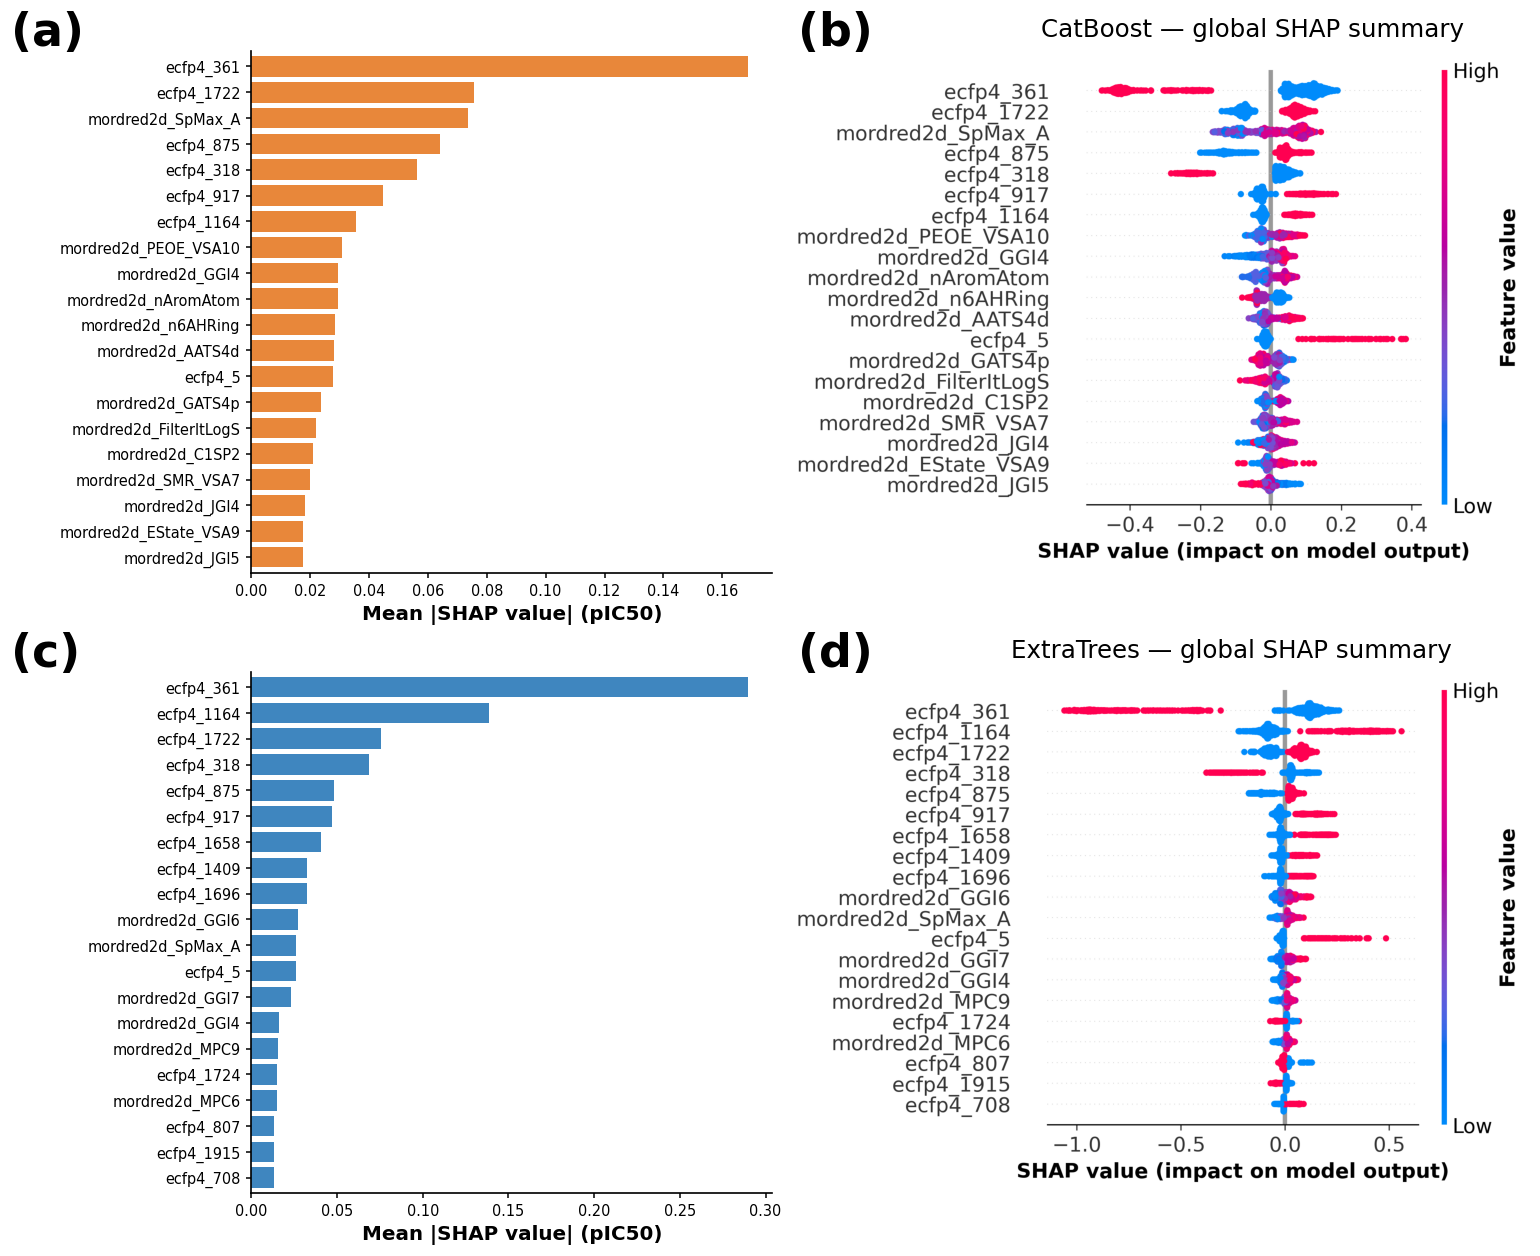

In [20]:
# ---- 5. Figure 2 - global SHAP importance and summary plots (a-d) : readable-at-page-width version ----
# Strategy: build the figure at ~page size (8.2 x 9.4 in, shown at 6.5 in in the manuscript) so fonts are
# only shrunk ~20%, and make every text element larger and bold. Render each beeswarm at the exact
# physical size of its slot so the raster is placed 1:1.
FIG_W, FIG_H = 14.0, 11.8          # landscape; shown at ~9 in wide on a landscape page (or 6.5 in on a portrait page)
LEFT, RIGHT, TOP, BOTTOM = 0.16, 0.99, 0.945, 0.065
WIDTH_RATIOS = [0.70, 1.0]
HSPACE, WSPACE = 0.19, 0.02
FS_TICK_BAR, FS_TICK_DOT, FS_LABEL, FS_TITLE_BAR, FS_TITLE_DOT, FS_PANEL = 9.5, 13, 13, 11.5, 16, 30
MODEL_BAR_COLOR = {"CatBoostRegressor": "#E8873A", "ExtraTreesRegressor": "#3F86BF"}

def _style(texts, size, weight="normal"):
    for t in texts:
        t.set_fontsize(size); t.set_fontweight(weight)

def importance_bars(ax, model_name, top_n=TOP_N_GLOBAL):
    top = global_imp[global_imp.model == model_name].head(top_n).iloc[::-1]
    ax.barh(top.feature, top.mean_abs_shap, color=MODEL_BAR_COLOR[model_name], height=0.8)
    ax.set_xlabel("Mean |SHAP value| (pIC50)", fontsize=FS_LABEL, fontweight="bold")
    ax.tick_params(axis="y", labelsize=FS_TICK_BAR, width=1.0)
    ax.tick_params(axis="x", labelsize=FS_TICK_BAR, width=1.0)
    _style(ax.get_yticklabels(), FS_TICK_BAR); _style(ax.get_xticklabels(), FS_TICK_BAR)
    ax.margins(y=0.01)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_linewidth(1.1)

def beeswarm_array(model_name, slot_w, slot_h, top_n=TOP_N_GLOBAL):
    """Render shap.summary_plot at the physical size of its slot, with larger bold text, and return a raster."""
    fig_b = plt.figure(figsize=(slot_w, slot_h))
    shap.summary_plot(shap_by_model[model_name].to_numpy(), X_test[selected_features], feature_names=selected_features,
                      max_display=top_n, show=False, plot_size=(slot_w, slot_h))
    ax = fig_b.axes[0]
    _style(ax.get_yticklabels(), FS_TICK_DOT); _style(ax.get_xticklabels(), FS_TICK_DOT)
    ax.xaxis.label.set_fontsize(FS_LABEL); ax.xaxis.label.set_fontweight("bold")
    if len(fig_b.axes) > 1:                      # colour bar: "Feature value", High / Low
        cb = fig_b.axes[-1]
        cb.yaxis.label.set_fontsize(FS_LABEL); cb.yaxis.label.set_fontweight("bold")
        _style(cb.get_yticklabels(), FS_TICK_DOT)
    fig_b.tight_layout()
    fig_b.canvas.draw()
    p = ax.get_position()
    centre = (p.x0 + p.x1) / 2                       # horizontal centre of the swarm axes, as a fraction of the slot
    arr = render_to_array(fig_b)
    cols = np.where((arr < 245).any(axis=2).any(axis=0))[0]
    left = cols.min() / arr.shape[1]                 # left edge of the first visible text (feature names)
    return arr, centre, left

ROW_MODELS = ["CatBoostRegressor", "ExtraTreesRegressor"]          # row 1 = CatBoost (a, b), row 2 = ExtraTrees (c, d)

fig = plt.figure(figsize=(FIG_W, FIG_H))
gs = fig.add_gridspec(2, 2, width_ratios=WIDTH_RATIOS, hspace=HSPACE, wspace=WSPACE,
                      left=LEFT, right=RIGHT, top=TOP, bottom=BOTTOM)
# physical size (inches) of the right-hand slot, so the beeswarm raster is placed 1:1
pos = gs[0, 1].get_position(fig)
slot_w, slot_h = pos.width * FIG_W, pos.height * FIG_H
dot_info = {m: beeswarm_array(m, slot_w, slot_h) for m in ROW_MODELS}

for row, m in enumerate(ROW_MODELS):
    ax_bar = fig.add_subplot(gs[row, 0])
    importance_bars(ax_bar, m)
    ax_dot = fig.add_subplot(gs[row, 1])
    arr, centre, left = dot_info[m]
    ax_dot.imshow(arr, aspect="auto")
    ax_dot.axis("off")
    ax_dot.text(centre, 1.0 + 6 / 72 / slot_h, f"{MODEL_SHORT[m]} \u2014 global SHAP summary", transform=ax_dot.transAxes,
                fontsize=FS_TITLE_DOT, ha="center", va="bottom")

# panel letters: all on the same baseline per row; (a)/(c) at the left edge of the figure,
# (b)/(d) at the left edge of the right-hand column
for row in range(2):
    y = gs[row, 0].get_position(fig).y1 + (6 + FS_TITLE_BAR / 2) / 72 / FIG_H     # vertical centre of the titles
    fig.text(0.004, y, "(" + "ac"[row] + ")", fontsize=FS_PANEL, fontweight="bold", va="center", ha="left")
    p1 = gs[row, 1].get_position(fig)
    fig.text(p1.x0 + dot_info[ROW_MODELS[row]][2] * p1.width, y, "(" + "bd"[row] + ")", fontsize=FS_PANEL, fontweight="bold", va="center", ha="left")
save_figure(fig, "Figure2_global_SHAP_importance_and_summary", svg=False)
plt.show()

## Figure 3 and Table 3 — Local SHAP waterfalls (Section 3.4)
Six compounds are explained locally: the highest-, median- and lowest-predicted test compound of each tree model. The compounds come from the current Stage-08 predictions by predicted pIC50 only, exactly as in Stage 10, Section 9a: the predictions of each model are sorted ascending, and the last row is the highest, row `n // 2` the median and the first row the lowest. Observed pIC50 is shown for reporting only.

In [6]:
# 6. The six locally explained compounds: highest / median / lowest predicted locked-test compound per model
def representative_cases(model_name):
    """Same selection as Stage 10, Section 9a (predicted pIC50 only)."""
    pred = (predictions.loc[predictions.model == model_name]
            .sort_values("predicted_pIC50", kind="stable").reset_index(drop=True))
    n = len(pred)
    return [("highest", pred.iloc[n - 1]), ("median", pred.iloc[n // 2]), ("lowest", pred.iloc[0])]

case_rows = []
for model_name in ROW_MODELS:
    for group, r in representative_cases(model_name):
        cid = r.chembl_id
        if cid not in test_index:
            raise KeyError(f"{cid} (from the Stage-08 predictions) is not in the locked test set.")
        case_rows.append({"model": model_name, "group": group, "chembl_id": cid,
                          "predicted_pIC50": float(r.predicted_pIC50), "observed_pIC50": float(r.observed_pIC50),
                          "baseline": base_values[model_name]})
cases = pd.DataFrame(case_rows)
cases.to_csv(TAB_DIR / "local_cases.csv", index=False)
display(cases.round(3))

# Table 3 (long form): every feature among the largest |SHAP| of each case
t3 = []
for r in cases.itertuples():
    local = shap_by_model[r.model].loc[r.chembl_id]
    top = local.reindex(local.abs().sort_values(ascending=False, kind="stable").index[:TOP_N_LOCAL])
    for rank, (feat, val) in enumerate(top.items(), start=1):
        raw_val = float(X_test.at[r.chembl_id, feat])
        t3.append({"model": r.model, "group": r.group, "chembl_id": r.chembl_id, "rank_by_abs_shap": rank, "feature": feat,
                   "feature_value": raw_val, "present": (raw_val >= 0.5) if feat.startswith("ecfp4_") else np.nan,
                   "shap_pIC50": float(val)})
table3 = pd.DataFrame(t3)
table3.to_csv(TAB_DIR / "table3_local_shap_contributions_long.csv", index=False)

,model,group,chembl_id,predicted_pIC50,observed_pIC50,baseline
0,CatBoostRegressor,highest,CHEMBL6010533,9.344,8.337,6.23
1,CatBoostRegressor,median,CHEMBL4206831,6.176,4.469,6.23
2,CatBoostRegressor,lowest,CHEMBL4788775,3.227,2.943,6.23
3,ExtraTreesRegressor,highest,CHEMBL6010533,9.101,8.337,6.23
4,ExtraTreesRegressor,median,CHEMBL5819331,6.196,5.919,6.23
5,ExtraTreesRegressor,lowest,CHEMBL4788775,3.302,2.943,6.23


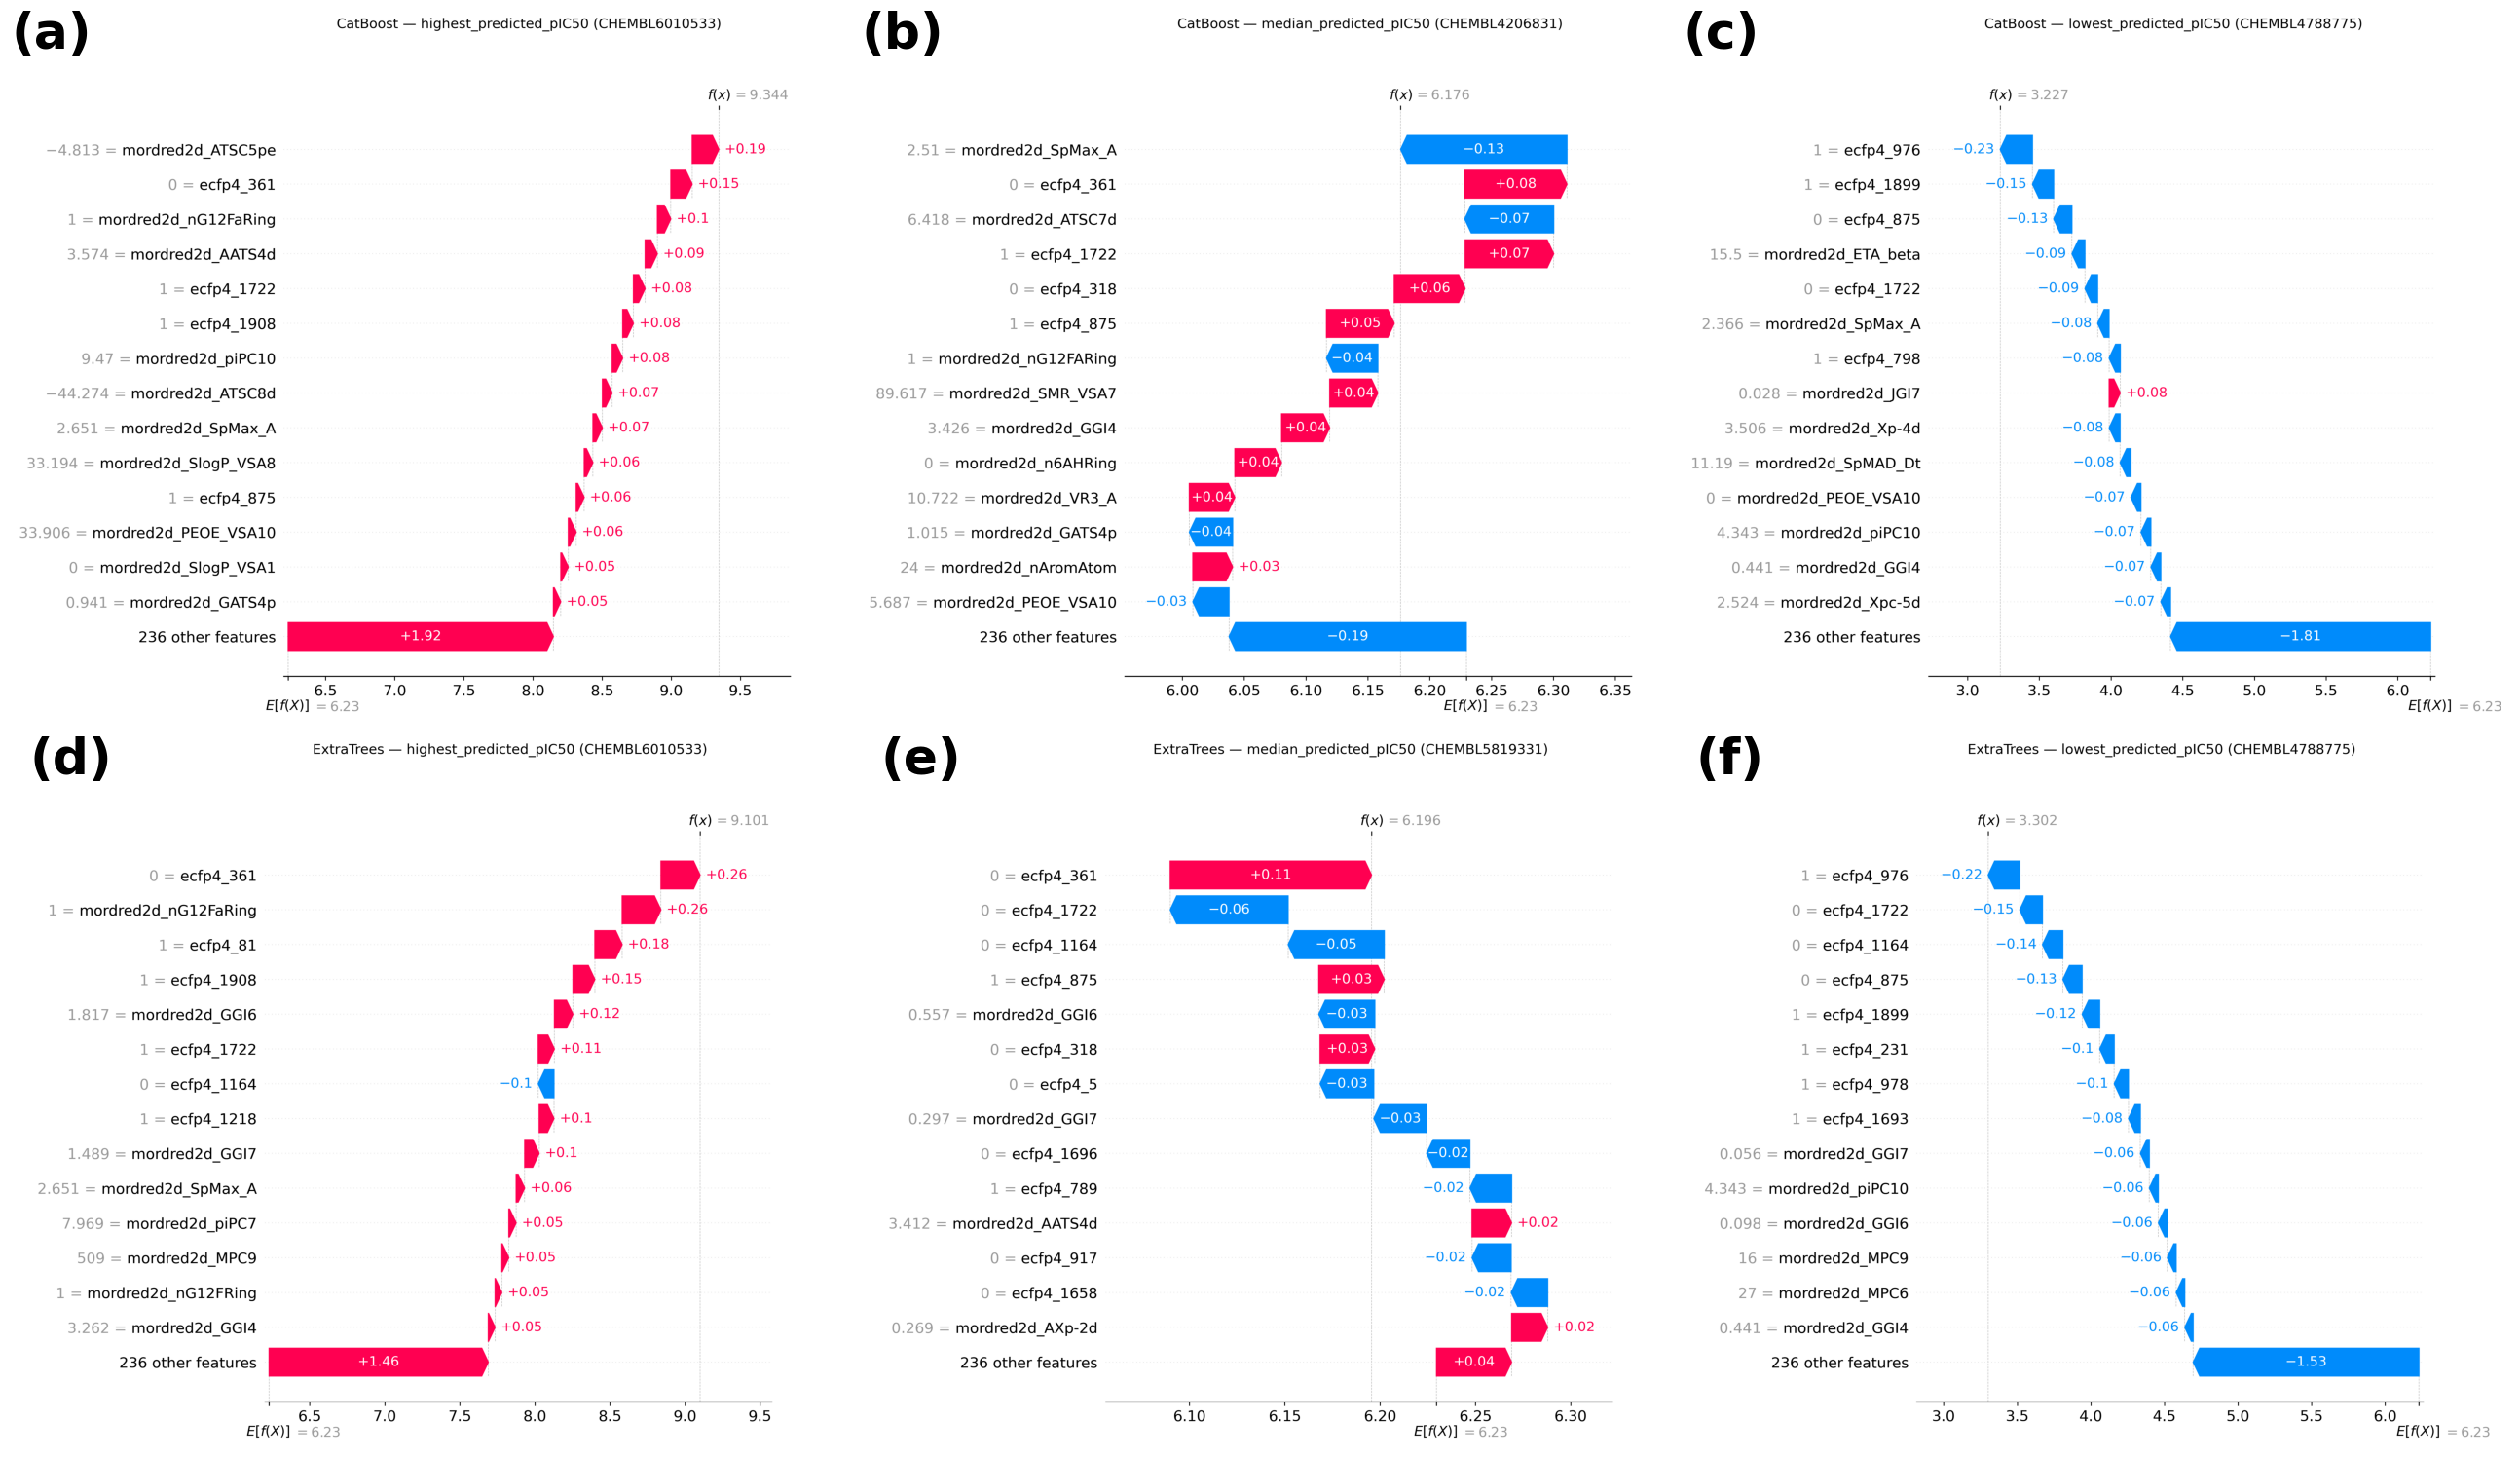

In [7]:
# 7. Figure 3 - local SHAP waterfall plots (a-c CatBoost, d-f ExtraTrees)
def waterfall_array(model_name, cid, group):
    explanation = shap.Explanation(values=shap_by_model[model_name].loc[cid].to_numpy(dtype=float),
                                   base_values=base_values[model_name],
                                   data=X_test.loc[cid, selected_features].to_numpy(dtype=float),
                                   feature_names=list(selected_features))
    shap.plots.waterfall(explanation, max_display=WATERFALL_MAX_DISPLAY, show=False)
    fig = plt.gcf()
    fig.suptitle(f"{MODEL_SHORT[model_name]} \u2014 {group}_predicted_pIC50 ({cid})", fontsize=12, y=1.005)
    return render_to_array(fig)

panel_arrays = [waterfall_array(r.model, r.chembl_id, r.group) for r in cases.itertuples()]
cell_w = max(a.shape[1] for a in panel_arrays) / SAVE_DPI
cell_h = max(a.shape[0] for a in panel_arrays) / SAVE_DPI

fig, axes = plt.subplots(2, 3, figsize=(3 * cell_w, 2 * cell_h), gridspec_kw={"wspace": 0.02, "hspace": 0.02})
for k, (ax, arr) in enumerate(zip(axes.ravel(), panel_arrays)):
    ax.imshow(arr)
    ax.axis("off")
    ax.text(0.0, 1.0, f"({'abcdef'[k]})", transform=ax.transAxes, fontsize=34, fontweight="bold", va="top", ha="left")
save_figure(fig, "Figure3_local_SHAP_waterfalls", svg=False)
plt.show()

## Figure 4 and Table A1 — Morgan environments mapped onto the six compounds
For each compound, every **present** Morgan bit among the 12 largest |SHAP| terms is traced back to its atom environment (centre atom + radius) with RDKit's `bitInfo`. Colours identify bits, not the direction of effect; on shared atoms the bit with the larger |SHAP| is drawn. The legend gives each bit's environment fragment SMILES, computed from the molecule. Present/absent status of every top bit is cross-checked against a freshly generated fingerprint, and the cell stops on any disagreement.

In [8]:
# 8. Morgan-environment helpers (same logic as Stage 10, Sections 6 and 9a)
BIT_PALETTE = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#17becf",
               "#bcbd22", "#393b79", "#637939", "#843c39"]

def bit_environments(mol):
    """bit -> list of (centre atom, radius) occurrences in this molecule, plus the set of bits that are on."""
    ao = rdFingerprintGenerator.AdditionalOutput()
    ao.AllocateBitInfoMap()
    fp = MORGAN.GetFingerprint(mol, additionalOutput=ao)
    return dict(ao.GetBitInfoMap()), set(map(int, fp.GetOnBits()))

def environment_indices(mol, centre, radius):
    bonds = [int(b) for b in Chem.FindAtomEnvironmentOfRadiusN(mol, int(radius), int(centre))]
    atoms = {int(centre)}
    for b in bonds:
        bond = mol.GetBondWithIdx(b)
        atoms.update((bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()))
    return sorted(atoms), sorted(bonds)

def fragment_strings(mol, atom_ids, bond_ids):
    """SMARTS and Kekule fragment SMILES of one environment; retries without stereo if the cut crosses a stereo bond."""
    stereo_free = Chem.Mol(mol)
    Chem.RemoveStereochemistry(stereo_free)
    errors = []
    for source, isomeric, note in ((mol, True, "stereo_preserved"), (stereo_free, True, "stereo_removed_at_boundary"),
                                   (stereo_free, False, "nonisomeric_fallback")):
        try:
            with rdBase.BlockLogs():
                smarts = Chem.MolFragmentToSmarts(source, atomsToUse=atom_ids, bondsToUse=bond_ids, isomericSmarts=isomeric)
                smiles = Chem.MolFragmentToSmiles(source, atomsToUse=atom_ids, bondsToUse=bond_ids, isomericSmiles=isomeric,
                                                  canonical=True, kekuleSmiles=True)
            if smarts and smiles:
                return smarts, smiles, note
        except Exception as exc:
            errors.append(str(exc))
    raise RuntimeError("Could not serialise this Morgan environment: " + " | ".join(errors))

def hex_to_rgba(hex_colour, alpha=0.78):
    v = hex_colour.lstrip("#")
    return (*(int(v[i:i + 2], 16) / 255 for i in (0, 2, 4)), alpha)

def map_case(model_name, cid):
    """Present Morgan bits among the TOP_N_LOCAL largest |SHAP| terms of one molecule, with their atom environments."""
    mol = Chem.MolFromSmiles(smiles_by_id[cid])
    if mol is None:
        raise ValueError(f"RDKit could not parse the SMILES of {cid}.")
    bit_info, on_bits = bit_environments(mol)
    local = shap_by_model[model_name].loc[cid]
    top = local.reindex(local.abs().sort_values(ascending=False, kind="stable").index[:TOP_N_LOCAL])
    items = []
    for feat, val in top.items():
        if not feat.startswith("ecfp4_"):
            continue
        bit = int(feat.rsplit("_", 1)[1])
        present = float(X_test.at[cid, feat]) >= 0.5
        if present != (bit in on_bits):
            raise ValueError(f"{cid} {feat}: feature matrix says present={present} but the regenerated fingerprint disagrees. "
                             "Check standardisation / fingerprint settings before interpreting the mapping.")
        if not present:
            continue                       # absent bits contribute to the prediction but have no atoms to draw
        atoms, bonds, occurrences = set(), set(), []
        for occ_no, (centre, radius) in enumerate(bit_info[bit], start=1):
            a_ids, b_ids = environment_indices(mol, centre, radius)
            smarts, frag, note = fragment_strings(mol, a_ids, b_ids)
            atoms.update(a_ids); bonds.update(b_ids)
            occurrences.append({"occurrence": occ_no, "centre_atom_0based": int(centre), "radius": int(radius),
                                "atom_indices_0based": ",".join(map(str, a_ids)), "SMARTS": smarts, "fragment_SMILES": frag, "note": note})
        items.append({"feature": feat, "bit": bit, "shap": float(val), "n_occ": len(occurrences), "atoms": atoms,
                      "bonds": bonds, "occurrences": occurrences})
    for k, item in enumerate(items):
        item["color"] = BIT_PALETTE[k % len(BIT_PALETTE)]
    return mol, items

def draw_highlighted(mol, items, size=(1000, 600)):
    """RDKit drawing with every mapped environment highlighted; on shared atoms/bonds the larger |SHAP| wins."""
    atom_pick, bond_pick = {}, {}
    for it in items:
        rgba = hex_to_rgba(it["color"])
        for a in it["atoms"]:
            if a not in atom_pick or abs(it["shap"]) > abs(atom_pick[a][1]):
                atom_pick[a] = (rgba, it["shap"])
        for b in it["bonds"]:
            if b not in bond_pick or abs(it["shap"]) > abs(bond_pick[b][1]):
                bond_pick[b] = (rgba, it["shap"])
    drawer = rdMolDraw2D.MolDraw2DCairo(*size)
    opts = drawer.drawOptions()
    opts.padding = 0.06
    opts.bondLineWidth = 2
    drawer.DrawMolecule(mol, highlightAtoms=list(atom_pick), highlightBonds=list(bond_pick),
                        highlightAtomColors={a: v[0] for a, v in atom_pick.items()},
                        highlightBondColors={b: v[0] for b, v in bond_pick.items()})
    drawer.FinishDrawing()
    return np.asarray(Image.open(io.BytesIO(drawer.GetDrawingText())).convert("RGB"))

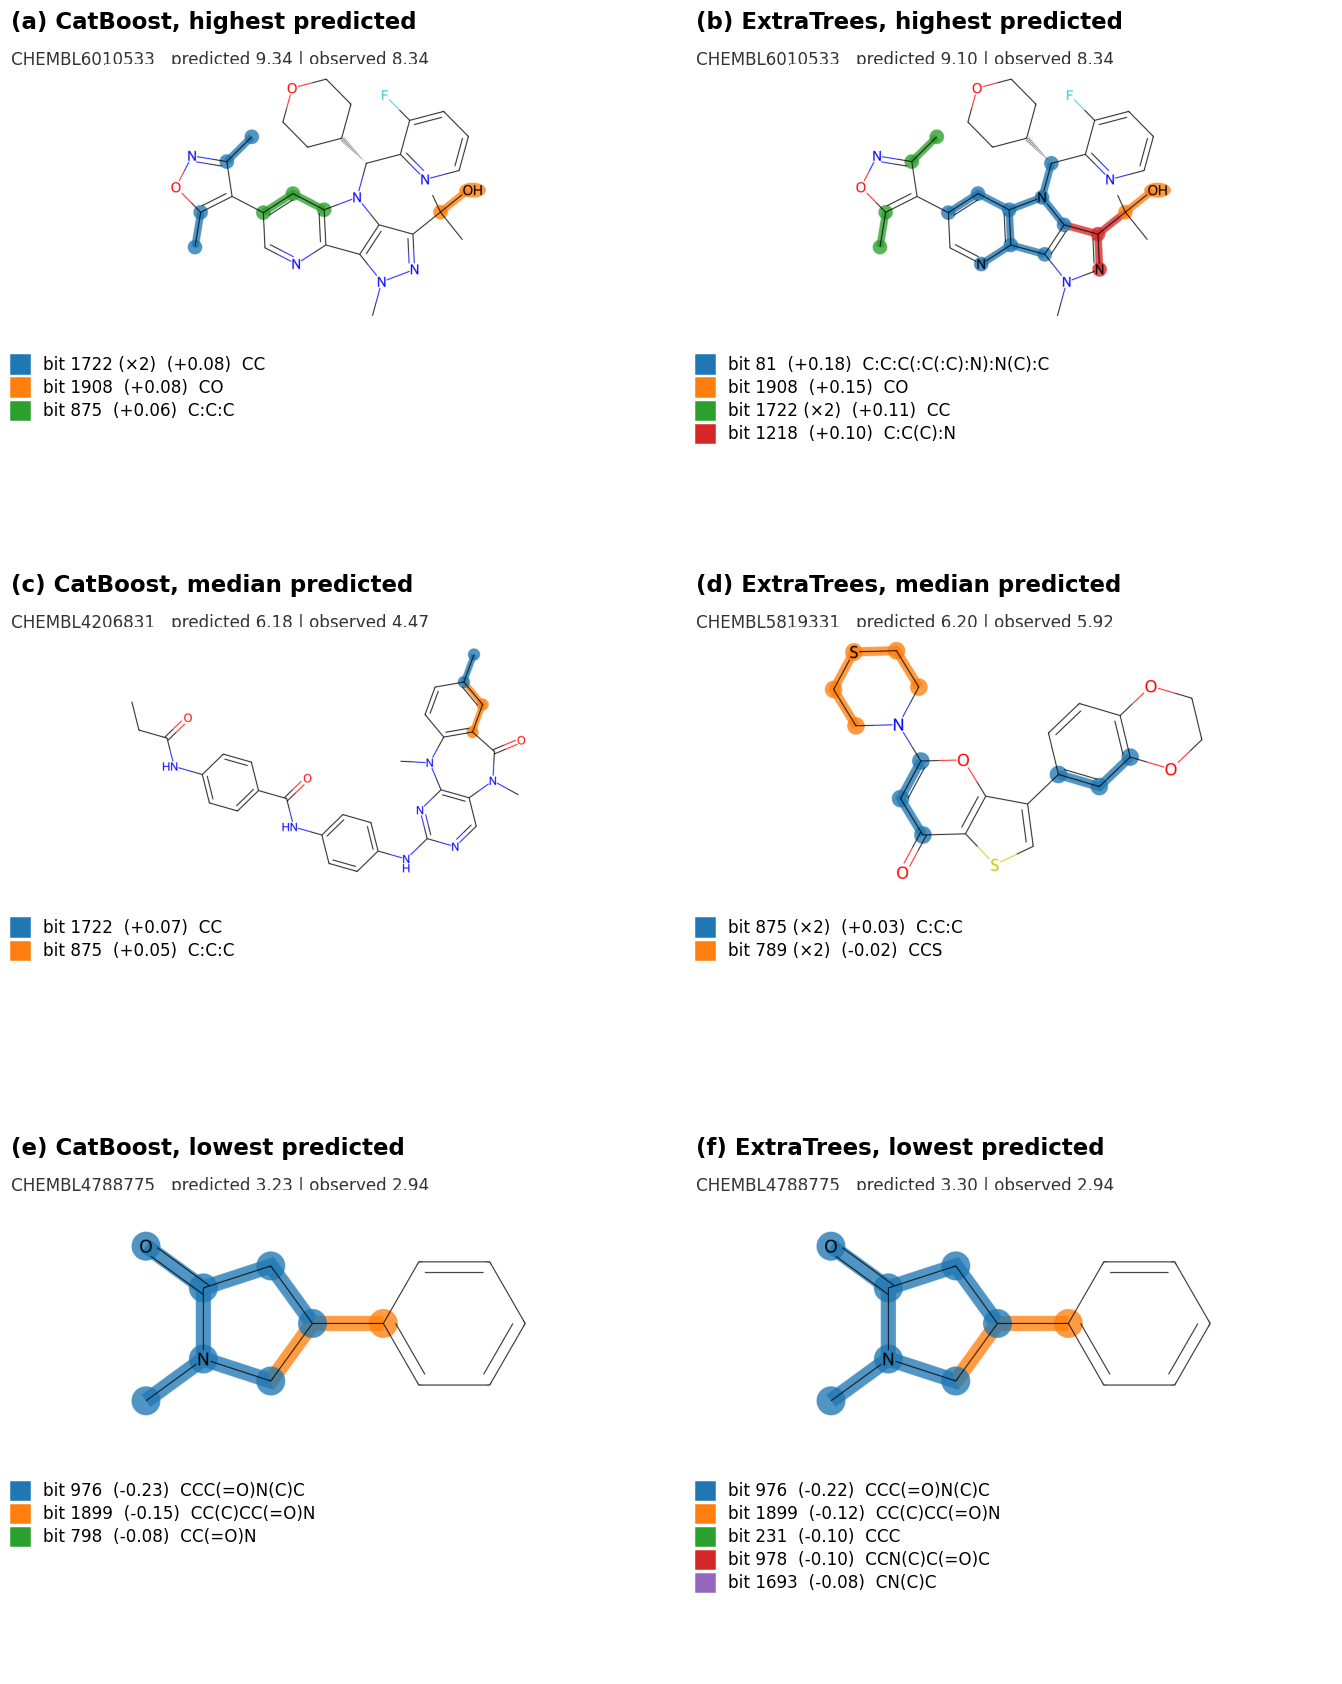

Mapped environment occurrences: 23 | bits drawn per panel: {('CatBoostRegressor', 'highest'): 3, ('CatBoostRegressor', 'lowest'): 3, ('CatBoostRegressor', 'median'): 2, ('ExtraTreesRegressor', 'highest'): 4, ('ExtraTreesRegressor', 'lowest'): 5, ('ExtraTreesRegressor', 'median'): 2}


In [9]:
# 9. Figure 4 - Morgan environments mapped onto the six compounds (3 rows x 2 columns)
FIG4_PANELS = [("a", "CatBoostRegressor", "highest"), ("b", "ExtraTreesRegressor", "highest"),
               ("c", "CatBoostRegressor", "median"),  ("d", "ExtraTreesRegressor", "median"),
               ("e", "CatBoostRegressor", "lowest"),  ("f", "ExtraTreesRegressor", "lowest")]
case_lookup = cases.set_index(["model", "group"])

fig = plt.figure(figsize=(12.5, 15.5))
gs = fig.add_gridspec(3, 2, hspace=0.05, wspace=0.08, left=0.03, right=0.99, top=0.985, bottom=0.01)
environment_rows = []
for k, (letter, model_name, group) in enumerate(FIG4_PANELS):
    row = case_lookup.loc[(model_name, group)]
    cid = row.chembl_id
    mol, items = map_case(model_name, cid)

    ax = fig.add_subplot(gs[k // 2, k % 2])
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
    ax.text(0.0, 1.0, f"({letter}) {MODEL_SHORT[model_name]}, {group} predicted", transform=ax.transAxes,
            fontsize=15, fontweight="bold", va="top")
    ax.text(0.0, 0.925, f"{cid}   predicted {row.predicted_pIC50:.2f} | observed {row.observed_pIC50:.2f}",
            transform=ax.transAxes, fontsize=11, color="#333333", va="top")
    img_ax = ax.inset_axes([0.0, 0.40, 1.0, 0.50])
    img_ax.imshow(draw_highlighted(mol, items))
    img_ax.axis("off")

    y = 0.34
    for it in items:
        ax.add_patch(Rectangle((0.0, y - 0.017), 0.03, 0.034, color=it["color"], transform=ax.transAxes, clip_on=False))
        note = it["occurrences"][0]["fragment_SMILES"]
        times = f" (\u00d7{it['n_occ']})" if it["n_occ"] > 1 else ""
        ax.text(0.05, y, f"bit {it['bit']}{times}  ({it['shap']:+.2f})  {note}", transform=ax.transAxes,
                fontsize=11, va="center")
        y -= 0.043
        for occ in it["occurrences"]:
            environment_rows.append({"model": model_name, "group": group, "chembl_id": cid, "bit": it["bit"],
                                     "local_SHAP_pIC50": it["shap"], "n_occurrences_of_bit": it["n_occ"], **occ,
                                     "source_SMILES": smiles_by_id[cid]})
save_figure(fig, "Figure4_mapped_Morgan_environments", svg=False)
plt.show()

table_a1 = pd.DataFrame(environment_rows)
table_a1.to_csv(TAB_DIR / "tableA1_mapped_morgan_environments.csv", index=False)
print("Mapped environment occurrences:", len(table_a1), "| bits drawn per panel:",
      table_a1.groupby(["model", "group"]).bit.nunique().to_dict())

In [10]:
# 10. Table 4 - calculated properties of the six locally explained compounds (RDKit, not model inputs)
rows = []
for r in cases.itertuples():
    mol = Chem.MolFromSmiles(smiles_by_id[r.chembl_id])
    rows.append({"Compound": r.chembl_id, "Case": f"{MODEL_SHORT[r.model]}, {r.group}",
                 "MW": round(Descriptors.MolWt(mol), 1), "cLogP": round(Crippen.MolLogP(mol), 2),
                 "TPSA": round(rdMolDescriptors.CalcTPSA(mol), 1), "HBA": Lipinski.NumHAcceptors(mol),
                 "HBD": Lipinski.NumHDonors(mol), "Aromatic rings": rdMolDescriptors.CalcNumAromaticRings(mol),
                 "Heavy atoms": mol.GetNumHeavyAtoms()})
table4 = pd.DataFrame(rows)
table4.to_csv(TAB_DIR / "table4_calculated_properties.csv", index=False)
display(table4)

,Compound,Case,MW,cLogP,TPSA,HBA,HBD,Aromatic rings,Heavy atoms
0,CHEMBL6010533,"CatBoost, highest",518.6,4.97,104.0,7,1,5,38
1,CHEMBL4206831,"CatBoost, median",535.6,5.49,119.6,7,3,4,40
2,CHEMBL4788775,"CatBoost, lowest",175.2,1.63,20.3,1,0,1,13
3,CHEMBL6010533,"ExtraTrees, highest",518.6,4.97,104.0,7,1,5,38
4,CHEMBL5819331,"ExtraTrees, median",387.5,3.85,51.9,7,0,3,26
5,CHEMBL4788775,"ExtraTrees, lowest",175.2,1.63,20.3,1,0,1,13


## Figure 5 — Agreement between ExtraTrees and CatBoost attributions
Every held-out molecule × every Morgan bit (all pairs, present or absent) gives one pair of local SHAP values, one per model. Correlations use all pairs; the plotted window is the central 99.5% of each marginal distribution.

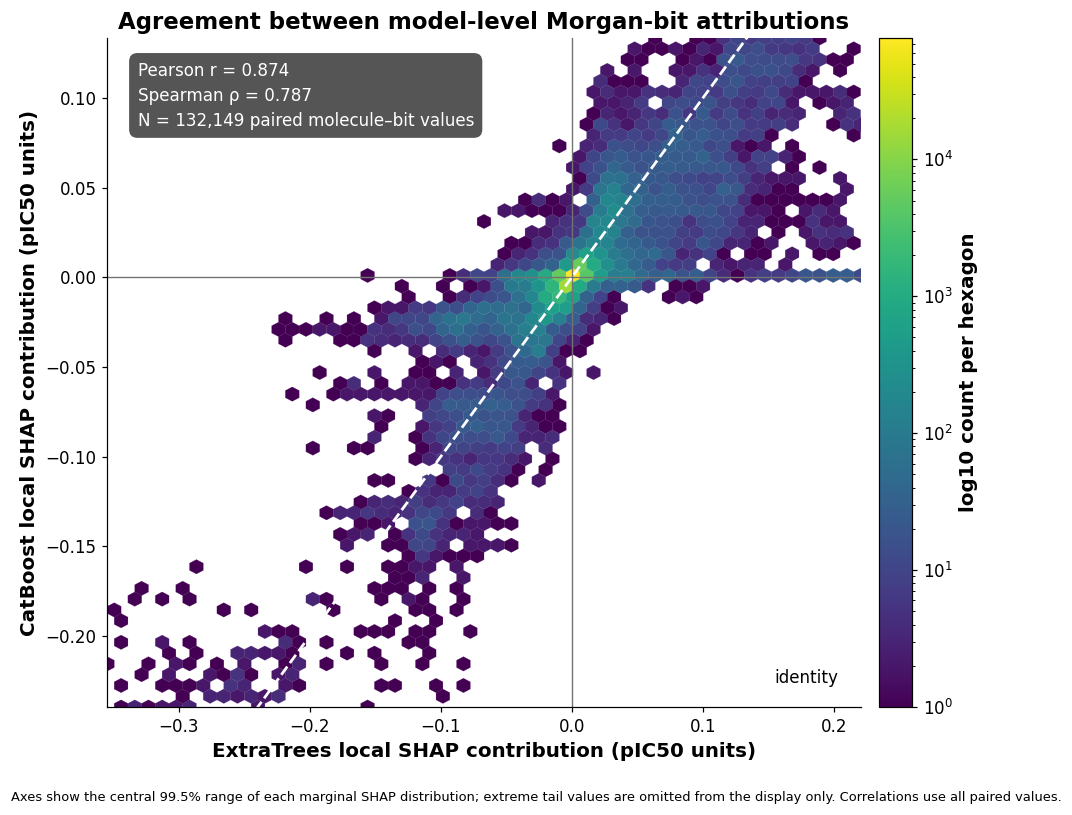

Pearson r = 0.874 | Spearman rho = 0.787 | pairs = 132,149


In [11]:
# 11. Figure 5 - hexbin agreement of local Morgan-bit attributions
et_vals = shap_by_model["ExtraTreesRegressor"][morgan_features].to_numpy(dtype=float).ravel()
cb_vals = shap_by_model["CatBoostRegressor"][morgan_features].to_numpy(dtype=float).ravel()
n_pairs = et_vals.size
pearson_r = float(stats.pearsonr(et_vals, cb_vals)[0])
spearman_rho = float(stats.spearmanr(et_vals, cb_vals)[0])

x_lo, x_hi = np.quantile(et_vals, [0.0025, 0.9975])
y_lo, y_hi = np.quantile(cb_vals, [0.0025, 0.9975])

fig, ax = plt.subplots(figsize=(9.4, 7.4))
hb = ax.hexbin(et_vals, cb_vals, gridsize=HEX_GRIDSIZE, extent=(x_lo, x_hi, y_lo, y_hi), mincnt=1,
               norm=LogNorm(), cmap="viridis", linewidths=0.15)
ax.set_xlim(x_lo, x_hi); ax.set_ylim(y_lo, y_hi)
ax.axhline(0, color="0.45", lw=0.9); ax.axvline(0, color="0.45", lw=0.9)
diag = (min(x_lo, y_lo), max(x_hi, y_hi))
ax.plot(diag, diag, color="white", ls="--", lw=1.8)
ax.text(0.97, 0.03, "identity", transform=ax.transAxes, ha="right", va="bottom", fontsize=11)
ax.text(0.04, 0.965, f"Pearson r = {pearson_r:.3f}\nSpearman \u03c1 = {spearman_rho:.3f}\nN = {n_pairs:,} paired molecule\u2013bit values",
        transform=ax.transAxes, ha="left", va="top", fontsize=11, color="white", linespacing=1.5,
        bbox=dict(boxstyle="round,pad=0.5", fc="#555555", ec="none"))
ax.set_xlabel("ExtraTrees local SHAP contribution (pIC50 units)", fontsize=13)
ax.set_ylabel("CatBoost local SHAP contribution (pIC50 units)", fontsize=13)
ax.set_title("Agreement between model-level Morgan-bit attributions", fontsize=15)
ax.tick_params(labelsize=11)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
cbar = fig.colorbar(hb, ax=ax, pad=0.02)
cbar.set_label("log10 count per hexagon", fontsize=13)
cbar.ax.tick_params(labelsize=11)
fig.text(0.01, 0.005, "Axes show the central 99.5% range of each marginal SHAP distribution; extreme tail values are omitted "
         "from the display only. Correlations use all paired values.", fontsize=8.5, ha="left")
fig.tight_layout(rect=(0, 0.03, 1, 1))
save_figure(fig, "Figure5_model_agreement_local_morgan_attributions")
plt.show()
print(f"Pearson r = {pearson_r:.3f} | Spearman rho = {spearman_rho:.3f} | pairs = {n_pairs:,}")

## Figures 6 and 7 and Table 5 — Recurring Morgan environments
For each Morgan bit the **carriers** are the test molecules where the model input is 1. Per bit the notebook computes (i) the mean local SHAP among carriers for each model and (ii) the observed median pIC50 of carriers minus noncarriers. Both get molecule-bootstrap 95% confidence intervals (`N_BOOT` resamples of test molecules). The environment label is the most frequent Morgan fragment of that bit across all carriers; `n_distinct_patterns` > 1 means the hashed bit is shared by several environments.

Which bits are drawn: among bits with at least `MIN_CARRIERS` carriers and the same sign of mean SHAP in both models, the `N_PER_DIRECTION` most positive and most negative by the average of the two models' means.

In [12]:
# 12. Carrier statistics for every Morgan bit, environment labels, bit selection and bootstrap CIs (Table 5)
rng = np.random.default_rng(SEED)

carrier = (X_test[morgan_features] >= 0.5)
obs = observed.to_numpy(dtype=float)
rows = []
for feat in morgan_features:
    mask = carrier[feat].to_numpy()
    n = int(mask.sum())
    if n == 0 or n == len(mask):
        continue
    rows.append({"feature": feat, "bit_id": int(feat.rsplit("_", 1)[1]), "n_carriers": n,
                 "mean_shap_ExtraTrees": float(shap_by_model["ExtraTreesRegressor"].loc[mask, feat].mean()),
                 "mean_shap_CatBoost": float(shap_by_model["CatBoostRegressor"].loc[mask, feat].mean()),
                 "median_obs_carriers": float(np.median(obs[mask])), "median_obs_noncarriers": float(np.median(obs[~mask])),
                 "median_delta_pIC50": float(np.median(obs[mask]) - np.median(obs[~mask]))})
bit_stats = pd.DataFrame(rows)
bit_stats["mean_shap_both_models"] = bit_stats[["mean_shap_ExtraTrees", "mean_shap_CatBoost"]].mean(axis=1)
bit_stats["direction"] = np.select(
    [(bit_stats.mean_shap_ExtraTrees > 0) & (bit_stats.mean_shap_CatBoost > 0),
     (bit_stats.mean_shap_ExtraTrees < 0) & (bit_stats.mean_shap_CatBoost < 0)], ["positive", "negative"], "models differ")

# --- which bits to draw
eligible = bit_stats[bit_stats.n_carriers >= MIN_CARRIERS]
pos = eligible[eligible.direction == "positive"].nlargest(N_PER_DIRECTION, "mean_shap_both_models")
neg = eligible[eligible.direction == "negative"].nsmallest(N_PER_DIRECTION, "mean_shap_both_models")
chosen = pd.concat([neg, pos]).feature.tolist()
if not chosen:
    raise RuntimeError("No recurring Morgan environments to plot; lower MIN_CARRIERS.")

# --- environment label per chosen bit: most frequent Morgan fragment over all carriers and occurrences
chosen_bits = {f: int(f.rsplit("_", 1)[1]) for f in chosen}
pattern_counts = {f: Counter() for f in chosen}
for cid in test_index:
    mol = Chem.MolFromSmiles(smiles_by_id[cid])
    bit_info, on_bits = bit_environments(mol)
    for feat, bit in chosen_bits.items():
        present = float(X_test.at[cid, feat]) >= 0.5
        if present != (bit in on_bits):
            raise ValueError(f"{cid} {feat}: feature matrix and regenerated fingerprint disagree.")
        if present:
            for centre, radius in bit_info[bit]:
                a_ids, b_ids = environment_indices(mol, centre, radius)
                pattern_counts[feat][fragment_strings(mol, a_ids, b_ids)[1]] += 1
pattern = {f: (c.most_common(1)[0][0] if c else "") for f, c in pattern_counts.items()}
n_patterns = {f: len(c) for f, c in pattern_counts.items()}

# --- bootstrap CIs (molecules are the resampling unit)
def boot_mean_ci(x, n_boot=N_BOOT):
    idx = rng.integers(0, len(x), size=(n_boot, len(x)))
    return np.percentile(x[idx].mean(axis=1), [2.5, 97.5])

def boot_median_diff_ci(mask, n_boot=N_BOOT):
    n = len(mask)
    diffs = np.full(n_boot, np.nan)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        m, y = mask[idx], obs[idx]
        if m.any() and (~m).any():
            diffs[b] = np.median(y[m]) - np.median(y[~m])
    return np.nanpercentile(diffs, [2.5, 97.5])

plot_rows = []
for feat in chosen:
    mask = carrier[feat].to_numpy()
    rec = bit_stats.loc[bit_stats.feature == feat].iloc[0].to_dict()
    for m in MODELS:
        vals = shap_by_model[m].loc[mask, feat].to_numpy(dtype=float)
        lo, hi = boot_mean_ci(vals)
        rec[f"mean_ci_lo_{MODEL_SHORT[m]}"], rec[f"mean_ci_hi_{MODEL_SHORT[m]}"] = lo, hi
    rec["delta_ci_lo"], rec["delta_ci_hi"] = boot_median_diff_ci(mask)
    rec["pattern"], rec["n_distinct_patterns"] = pattern[feat], n_patterns[feat]
    rec["label"] = f"{feat} | {pattern[feat]}"
    plot_rows.append(rec)
motif_stats = pd.DataFrame(plot_rows)
motif_stats.to_csv(TAB_DIR / "table5_fig6_fig7_recurring_morgan_environments.csv", index=False)
bit_stats.to_csv(TAB_DIR / "all_morgan_bit_carrier_statistics.csv", index=False)

display(motif_stats[["feature", "pattern", "n_carriers", "mean_shap_ExtraTrees", "mean_shap_CatBoost", "median_delta_pIC50",
                     "direction", "n_distinct_patterns"]].round(3))

,feature,pattern,n_carriers,mean_shap_ExtraTrees,mean_shap_CatBoost,median_delta_pIC50,direction,n_distinct_patterns
0,ecfp4_361,C:C(:C)C,324,-0.780,-0.382,-2.473,negative,4
1,ecfp4_318,CC(:N):N,152,-0.262,-0.223,-2.153,negative,2
2,ecfp4_1646,C:C(:C)NC(=O)C,62,-0.077,-0.121,-0.987,negative,5
3,ecfp4_1284,C/C=C/C(:C):C,34,-0.062,-0.101,-0.982,negative,4
4,ecfp4_1470,C:C:C:C(:C)N,48,-0.079,-0.076,-1.027,negative,4
5,ecfp4_1589,CNC,58,-0.071,-0.027,-0.743,negative,4
6,ecfp4_231,CCC,88,-0.064,-0.025,-1.003,negative,5
7,ecfp4_1164,C:N:N,289,0.349,0.074,1.706,positive,1
8,ecfp4_5,CC(=O)N,77,0.202,0.220,0.431,positive,5
9,ecfp4_917,CC(:N):N,247,0.132,0.107,1.609,positive,2


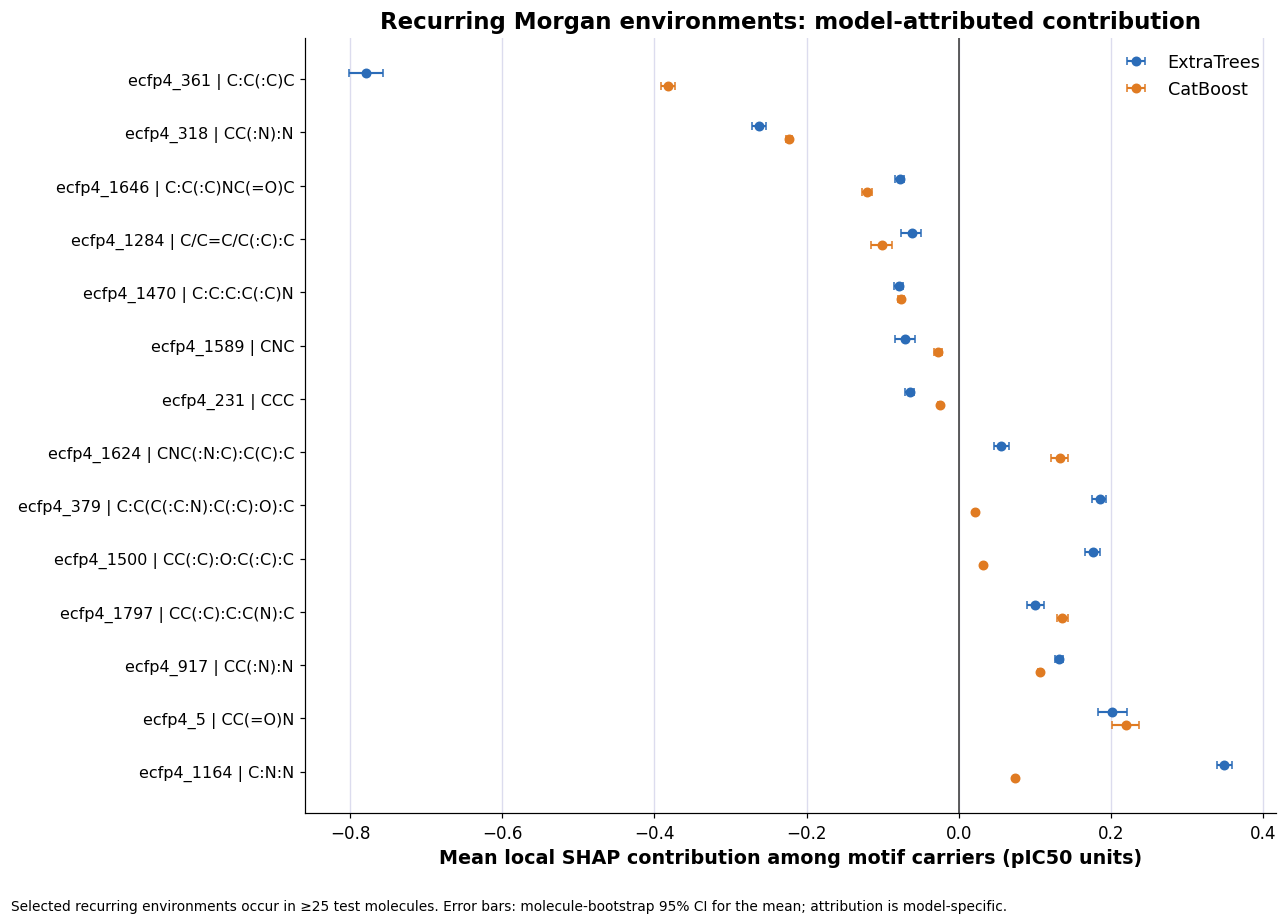

In [13]:
# 13. Figure 6 - mean local SHAP among carriers of each recurring Morgan environment
FOREST_COLOR = {"ExtraTreesRegressor": "#2B6CB8", "CatBoostRegressor": "#E07B22"}
d6 = motif_stats.sort_values("mean_shap_both_models").reset_index(drop=True)   # most negative on top
ypos = np.arange(len(d6))[::-1]
offset = {"ExtraTreesRegressor": 0.12, "CatBoostRegressor": -0.12}

fig, ax = plt.subplots(figsize=(11.8, 8.4))
ax.axvline(0, color="0.2", lw=1.0, zorder=1)
ax.grid(axis="x", color="#dcdcee", lw=0.9, zorder=0)
ax.set_axisbelow(True)
for m in MODELS:
    short = MODEL_SHORT[m]
    mean = d6[f"mean_shap_{short}"].to_numpy()
    lo, hi = d6[f"mean_ci_lo_{short}"].to_numpy(), d6[f"mean_ci_hi_{short}"].to_numpy()
    ax.errorbar(mean, ypos + offset[m], xerr=[np.clip(mean - lo, 0, None), np.clip(hi - mean, 0, None)], fmt="o", ms=5.5,
                color=FOREST_COLOR[m], ecolor=FOREST_COLOR[m], elinewidth=1.4, capsize=2.6, label=short, zorder=3)
ax.set_yticks(ypos)
ax.set_yticklabels(d6.label, fontsize=10.5)
ax.set_xlabel("Mean local SHAP contribution among motif carriers (pIC50 units)", fontsize=12.5)
ax.set_title("Recurring Morgan environments: model-attributed contribution", fontsize=15)
ax.legend(loc="upper right", frameon=False, fontsize=11.5)
ax.tick_params(axis="x", labelsize=11)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.text(0.01, 0.005, f"Selected recurring environments occur in \u2265{MIN_CARRIERS} test molecules. Error bars: molecule-bootstrap 95% CI "
         "for the mean; attribution is model-specific.", fontsize=9, ha="left")
fig.tight_layout(rect=(0, 0.03, 1, 1))
save_figure(fig, "Figure6_mean_local_SHAP_recurring_environments")
plt.show()

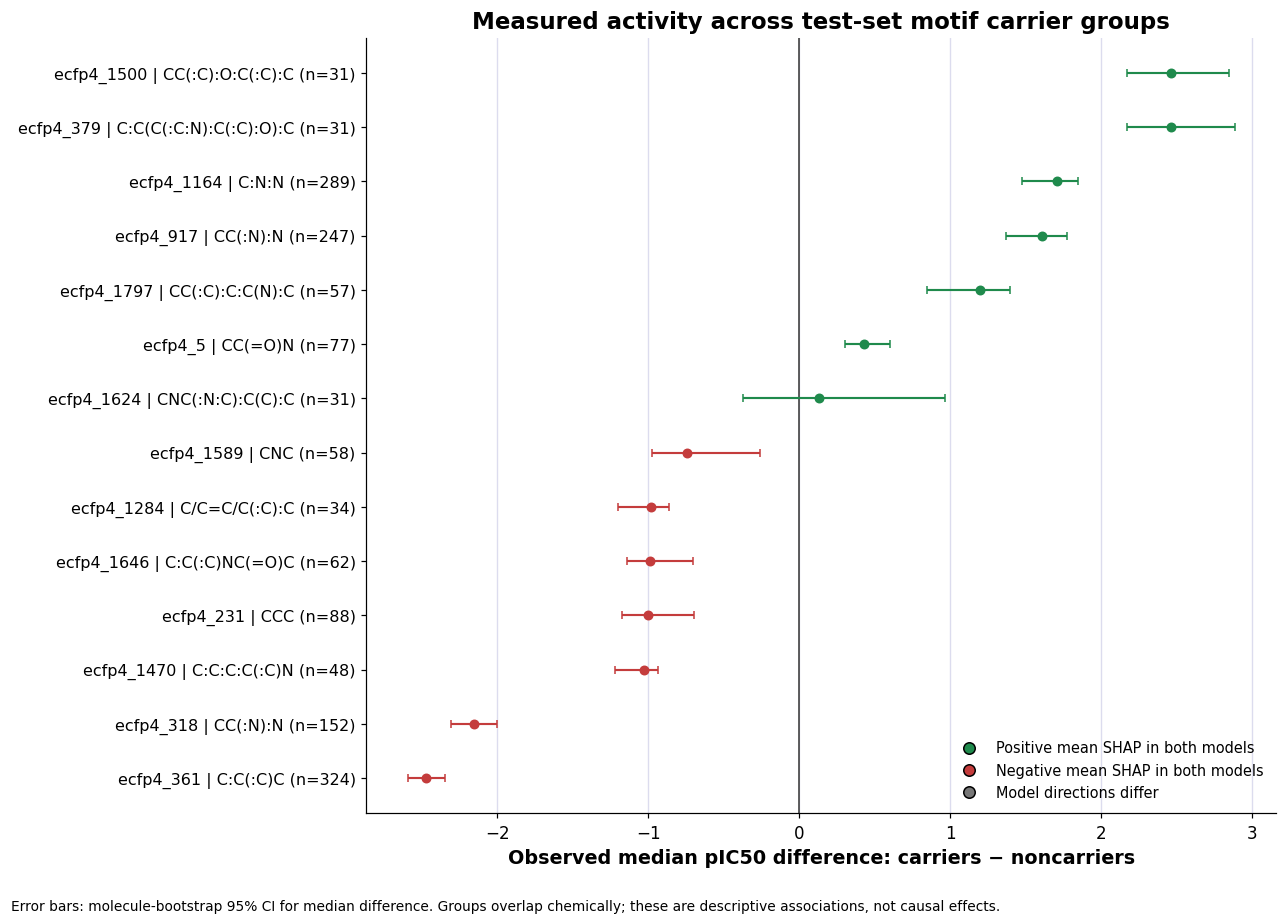

In [14]:
# 14. Figure 7 - observed activity difference, carriers vs noncarriers
DIRECTION_COLOR = {"positive": "#1f8a4c", "negative": "#c43c3c", "models differ": "#777777"}
d7 = motif_stats.sort_values("median_delta_pIC50", ascending=False).reset_index(drop=True)   # largest positive on top
ypos = np.arange(len(d7))[::-1]

fig, ax = plt.subplots(figsize=(11.8, 8.4))
ax.axvline(0, color="0.2", lw=1.0, zorder=1)
ax.grid(axis="x", color="#dcdcee", lw=0.9, zorder=0)
ax.set_axisbelow(True)
for y, r in zip(ypos, d7.itertuples()):
    colour = DIRECTION_COLOR[r.direction]
    ax.errorbar(r.median_delta_pIC50, y, xerr=[[max(r.median_delta_pIC50 - r.delta_ci_lo, 0)], [max(r.delta_ci_hi - r.median_delta_pIC50, 0)]],
                fmt="o", ms=5.5, color=colour, ecolor=colour, elinewidth=1.4, capsize=2.6, zorder=3)
ax.set_yticks(ypos)
ax.set_yticklabels([f"{r.label} (n={r.n_carriers})" for r in d7.itertuples()], fontsize=10.5)
ax.set_xlabel("Observed median pIC50 difference: carriers \u2212 noncarriers", fontsize=12.5)
ax.set_title("Measured activity across test-set motif carrier groups", fontsize=15)
legend_items = [Line2D([0], [0], marker="o", ls="", markerfacecolor=DIRECTION_COLOR[k], markeredgecolor="black", markersize=7.5, label=v)
                for k, v in (("positive", "Positive mean SHAP in both models"), ("negative", "Negative mean SHAP in both models"),
                             ("models differ", "Model directions differ"))]
ax.legend(handles=legend_items, loc="lower right", frameon=False, fontsize=9.5)
ax.tick_params(axis="x", labelsize=11)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.text(0.01, 0.005, "Error bars: molecule-bootstrap 95% CI for median difference. Groups overlap chemically; these are descriptive "
         "associations, not causal effects.", fontsize=9, ha="left")
fig.tight_layout(rect=(0, 0.03, 1, 1))
save_figure(fig, "Figure7_observed_activity_carriers_vs_noncarriers")
plt.show()

## Numbers for the manuscript text (current models)
Values quoted in Sections 3.3–3.4 of the text, recomputed from the current SHAP tables and predictions, so the prose and tables can be updated to match the new figures.

In [15]:
# 15. Numbers quoted in the text, from the current models
fam = family_share.set_index(["model", "family"]).share_of_summed_abs_SHAP_pct
rows = []
for m in MODELS:
    rows.append({"item": f"{MODEL_SHORT[m]}: top-5 features by mean |SHAP|", "value": ", ".join(global_imp[global_imp.model == m].feature.head(5))})
    for family in ("Morgan", "Mordred 2D", "Physicochemical"):
        if (m, family) in fam.index:
            rows.append({"item": f"{MODEL_SHORT[m]}: {family} share of summed |SHAP| (%)", "value": round(float(fam[(m, family)]), 1)})
    rows.append({"item": f"{MODEL_SHORT[m]}: baseline E[f(X)]", "value": round(base_values[m], 3)})
for r in cases.itertuples():
    rows.append({"item": f"{MODEL_SHORT[r.model]} {r.group}: {r.chembl_id} predicted / observed",
                 "value": f"{r.predicted_pIC50:.3f} / {r.observed_pIC50:.3f}"})
rows += [{"item": "Pearson r, ExtraTrees vs CatBoost Morgan-bit SHAP", "value": round(pearson_r, 3)},
         {"item": "Spearman rho", "value": round(spearman_rho, 3)},
         {"item": "Paired molecule-bit values", "value": f"{n_pairs:,}"}]
top_neg = bit_stats[bit_stats.n_carriers >= MIN_CARRIERS].nsmallest(1, "mean_shap_both_models")
for r in top_neg.itertuples():
    rows.append({"item": f"Most negative recurring bit: {r.feature} (n={r.n_carriers}) mean SHAP ET / CatBoost",
                 "value": f"{r.mean_shap_ExtraTrees:.3f} / {r.mean_shap_CatBoost:.3f}"})
mode_value = pd.Series(obs).round(4).value_counts().iloc[0:1]
rows.append({"item": "Most frequent observed pIC50 in the test set (value: molecules, % of test set)",
             "value": f"{mode_value.index[0]}: {int(mode_value.iloc[0])}, {100 * mode_value.iloc[0] / len(obs):.1f}%"})
text_numbers = pd.DataFrame(rows)
text_numbers.to_csv(TAB_DIR / "numbers_for_manuscript_text.csv", index=False)
with pd.option_context("display.max_colwidth", 120):
    display(text_numbers)

,item,value
0,ExtraTrees: top-5 features by mean |SHAP|,"ecfp4_361, ecfp4_1164, ecfp4_1722, ecfp4_318, ecfp4_875"
1,ExtraTrees: Morgan share of summed |SHAP| (%),67.8
2,ExtraTrees: Mordred 2D share of summed |SHAP| (%),32.1
3,ExtraTrees: Physicochemical share of summed |SHAP| (%),0.1
4,ExtraTrees: baseline E[f(X)],6.23
5,CatBoost: top-5 features by mean |SHAP|,"ecfp4_361, ecfp4_1722, mordred2d_SpMax_A, ecfp4_875, ecfp4_318"
6,CatBoost: Morgan share of summed |SHAP| (%),35.9
7,CatBoost: Mordred 2D share of summed |SHAP| (%),63.6
8,CatBoost: Physicochemical share of summed |SHAP| (%),0.6
9,CatBoost: baseline E[f(X)],6.23


In [16]:
# 16. Inventory of everything written
print("Folder:", FIG_DIR)
for p in saved_files:
    print("  figure:", p.name)
for p in sorted(TAB_DIR.glob("*.csv")):
    print("  table: ", p.name)

Folder: C:\Users\USER\Documents\E\Code\outputs\10_interpretation\manuscript_figures
  figure: Figure2_global_SHAP_importance_and_summary.png
  figure: Figure3_local_SHAP_waterfalls.png
  figure: Figure4_mapped_Morgan_environments.png
  figure: Figure5_model_agreement_local_morgan_attributions.png
  figure: Figure5_model_agreement_local_morgan_attributions.svg
  figure: Figure6_mean_local_SHAP_recurring_environments.png
  figure: Figure6_mean_local_SHAP_recurring_environments.svg
  figure: Figure7_observed_activity_carriers_vs_noncarriers.png
  figure: Figure7_observed_activity_carriers_vs_noncarriers.svg
  table:  all_morgan_bit_carrier_statistics.csv
  table:  family_share_of_abs_shap.csv
  table:  global_shap_importance_both_models.csv
  table:  local_cases.csv
  table:  manuscript_number_check.csv
  table:  numbers_for_manuscript_text.csv
  table:  table3_local_shap_contributions_long.csv
  table:  table4_calculated_properties.csv
  table:  table5_fig6_fig7_recurring_morgan_environm